# Analisis Geospasial Kebakaran Hutan dan Lahan (Karhutla)
## Fokus Kajian: Sebaran Titik Panas (*Hotspot*) di Pulau Sulawesi

**Tujuan.** Notebook ini menyajikan alur lengkap analisis data spasial titik panas kebakaran hutan dan lahan (*karhutla*). Analisis diawali dari gambaran makro kepulauan Indonesia secara utuh, kemudian mengerucut dan berfokus secara mendalam pada **Pulau Sulawesi** sebagai wilayah dengan konsentrasi titik panas tertinggi di data SiPongi KLHK. Seluruh tahapan mencakup pemuatan data, pembersihan data, eksplorasi data spasial vektor (`geopandas`), transformasi proyeksi koordinat (CRS), pembuatan zona bahaya (*buffer* 500 m), visualisasi tematik (*choropleth map* 6 provinsi), hingga pembuatan peta interaktif berbasis `plotly.express` (Mapbox).

---

### Lampiran Sumber & Sitasi Ilmiah Dataset

| No | Sumber | Berkas / Repositori | Keterangan |
|---|---|---|---|
| 1 | **NASA FIRMS** (VIIRS 375 m S-NPP, C2) | `DL_FIRE_SV-C2_839983.zip` / CSV Archive & NRT | Titik panas individual (lintang, bujur, FRP, kecerahan) |
| 2 | **SiPongi+ KLHK RI** | `sebaran-hotspot.xlsx` (Sheet `Akumulasi` & `Detail`) | Rekapitulasi jumlah hotspot per provinsi, kabupaten, hingga desa |
| 3 | **Batas Wilayah Administrasi 38 Provinsi** | `indonesia-38-provinces.geojson` | Data vektor batas garis pantai dan 38 provinsi Indonesia |
| 4 | **Repositori GitHub Sumber Data** | [github.com/YanDraa/ADS-KARHUTLA](https://github.com/YanDraa/ADS-KARHUTLA) | Repositori daring untuk kemudahan akses langsung di Colab/Jupyter |

#### 1. Atribusi & Sitasi NASA FIRMS
* **Penyedia Data:** NASA Earth Science Data and Information System (EOSDIS) — *Fire Information for Resource Management System* (FIRMS).
* **Sensor & Satelit:** VIIRS 375 m Active Fire Product (Collection 2) — satelit Suomi NPP, NOAA-20, dan NOAA-21.
* **Pernyataan Pengakuan (*Acknowledgement*):**
  > *"We acknowledge the use of data and/or imagery from NASA's Fire Information for Resource Management System (FIRMS) (https://earthdata.nasa.gov/firms), part of NASA's Earth Observing System Data and Information System (EOSDIS)."*
* **Referensi Ilmiah (Jurnal):**
  > Schroeder, W., Oliva, P., Giglio, L., & Csiszar, I. A. (2014). *The New VIIRS 375 m active fire detection data product: Algorithm description and initial assessment.* Remote Sensing of Environment, 143, 85–96. [https://doi.org/10.1016/j.rse.2013.12.008](https://doi.org/10.1016/j.rse.2013.12.008)

#### 2. Atribusi Data SiPongi+ (KLHK RI)
* **Instansi Pengelola:** Direktorat Pengendalian Kebakaran Hutan dan Lahan (Dit. PKHL), Ditjen Pengendalian Perubahan Iklim (PPI), Kementerian Lingkungan Hidup dan Kehutanan (KLHK) Republik Indonesia.
* **Portal Resmi:** [https://sipongi.menlhk.go.id/](https://sipongi.menlhk.go.id/)

---

**Struktur Analisis:**
0. Persiapan Lingkungan & Instalasi Pustaka
1. Pemuatan Data (*Data Loading*)
2. Pembersihan Data (*Data Cleaning*)
3. **Konteks Nasional:** Peta Sebaran Hotspot Kepulauan Indonesia (Wujud Pulau Nyata)
4. **Tugas 1:** Eksplorasi Data Spasial Dasar Titik Api Pulau Sulawesi
5. **Tugas 2:** Transformasi Proyeksi Koordinat CRS (`EPSG:4326` → `EPSG:3857`)
6. **Tugas 3:** Operasi Geometri *Buffer* 500 Meter (Zona Bahaya Karhutla)
7. **Tugas 4:** Visualisasi Tematik *Choropleth Map* 6 Provinsi di Pulau Sulawesi
8. **Tugas 5:** Peta Interaktif Mapbox Khusus Sulawesi (`plotly.express` & Ekspor Gambar)
9. Kesimpulan & Temuan Kunci

## 0. Persiapan Lingkungan & Instalasi Pustaka

Jalankan sel instalasi di bawah ini terlebih dahulu untuk memasang pustaka yang diperlukan jika belum tersedia di lingkungan kerja Anda.

In [51]:
# Instalasi pustaka pendukung analisis geospasial
%pip install geopandas openpyxl plotly kaleido matplotlib shapely

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


### 0.1 Import Pustaka
Setelah instalasi selesai, impor modul-modul analisis data dan spasial di bawah ini.

In [52]:
import io
import os
import urllib.request
import warnings
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
import plotly.express as px
from shapely.geometry import box

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})

print("Versi pustaka:")
print(f"- pandas    : {pd.__version__}")
print(f"- geopandas : {gpd.__version__}")

Versi pustaka:
- pandas    : 2.2.3
- geopandas : 1.2.0


Konfigurasi tautan sumber data daring (GitHub raw) dan berkas GeoJSON batas 38 provinsi Indonesia.

In [53]:
# Sumber data daring (GitHub raw & GeoJSON 38 provinsi)
GITHUB_RAW = "https://raw.githubusercontent.com/YanDraa/ADS-KARHUTLA/refs/heads/main"

URL_NASA_ARCHIVE = f"{GITHUB_RAW}/DL_FIRE_SV-C2_839983/fire_archive_SV-C2_839983.csv"
URL_NASA_NRT     = f"{GITHUB_RAW}/DL_FIRE_SV-C2_839983/fire_nrt_SV-C2_839983.csv"
URL_SIPONGI      = f"{GITHUB_RAW}/sebaran-hotspot.xlsx"
URL_GEOJSON_INDO = (
    "https://raw.githubusercontent.com/denyherianto/"
    "indonesia-geojson-topojson-maps-with-38-provinces/main/GeoJSON/"
    "indonesia-38-provinces.geojson"
)

BASE_DIR              = Path(".")
PATH_GEOJSON_SULAWESI = BASE_DIR / "hotspot_sulawesi.geojson"

# Bounding box koordinat Pulau Sulawesi
BBOX_SULAWESI = {"lon_min": 118.5, "lon_max": 125.5, "lat_min": -6.5, "lat_max": 2.5}

## 1. Pemuatan Data (*Data Loading*)

### 1.1 Memuat Poligon Batas Wilayah Administrasi Indonesia & Sulawesi
Membaca GeoJSON 38 provinsi Indonesia via URL, lalu menyaring khusus 6 provinsi di Pulau Sulawesi:
1. Sulawesi Selatan
2. Sulawesi Tenggara
3. Sulawesi Tengah
4. Sulawesi Barat
5. Gorontalo
6. Sulawesi Utara

In [54]:
# Memuat batas administrasi 38 provinsi Indonesia
gdf_indonesia = gpd.read_file(URL_GEOJSON_INDO)

if gdf_indonesia.crs is None:
    gdf_indonesia = gdf_indonesia.set_crs(epsg=4326)
else:
    gdf_indonesia = gdf_indonesia.to_crs(epsg=4326)

# Memfilter 6 provinsi di Pulau Sulawesi
daftar_prov_sulawesi = [
    "Sulawesi Selatan", "Sulawesi Tenggara", "Sulawesi Tengah",
    "Sulawesi Barat", "Gorontalo", "Sulawesi Utara"
]
pola_sulawesi = "|".join(daftar_prov_sulawesi)
gdf_sulawesi = gdf_indonesia[
    gdf_indonesia["PROVINSI"].str.contains(pola_sulawesi, case=False, na=False)
].copy().reset_index(drop=True)

print(f"Total poligon Indonesia : {len(gdf_indonesia)} provinsi")
print(f"Total poligon Sulawesi  : {len(gdf_sulawesi)} provinsi")
display(gdf_sulawesi[["PROVINSI", "geometry"]])

Total poligon Indonesia : 38 provinsi
Total poligon Sulawesi  : 6 provinsi


,PROVINSI,geometry
0,Sulawesi Tengah,"MULTIPOLYGON (((119.56117 -0.84951, 119.59325 ..."
1,Sulawesi Barat,"POLYGON ((119.56117 -0.84951, 119.30326 -1.273..."
2,Sulawesi Selatan,"MULTIPOLYGON (((120.92375 -7.28328, 120.79523 ..."
3,Gorontalo,"POLYGON ((121.33669 0.47382, 121.52372 0.54927..."
4,Sulawesi Tenggara,"MULTIPOLYGON (((121.84203 -5.33502, 121.94663 ..."
5,Sulawesi Utara,"MULTIPOLYGON (((123.47365 0.32026, 124.51201 0..."


### 1.2 Memuat Data Titik Panas NASA FIRMS
Dua file data NASA FIRMS (arsip terverifikasi dan *near real-time*) digabungkan menjadi satu DataFrame.

In [55]:
# Memuat data titik api NASA FIRMS
df_archive = pd.read_csv(URL_NASA_ARCHIVE, dtype={"acq_time": str})
df_nrt     = pd.read_csv(URL_NASA_NRT, dtype={"acq_time": str})

df_archive["sumber"] = "archive"
df_nrt["sumber"]     = "nrt"

df_nasa_raw = pd.concat([df_archive, df_nrt], ignore_index=True)

print(f"NASA Archive : {len(df_archive):>8,} baris ({df_archive['acq_date'].min()} s.d. {df_archive['acq_date'].max()})")
print(f"NASA NRT     : {len(df_nrt):>8,} baris ({df_nrt['acq_date'].min()} s.d. {df_nrt['acq_date'].max()})")
print(f"Total Mentah : {len(df_nasa_raw):>8,} baris, {df_nasa_raw.shape[1]} kolom")
df_nasa_raw.head()

NASA Archive :   54,304 baris (2026-01-01 s.d. 2026-07-31)
NASA NRT     :  571,763 baris (2026-08-01 s.d. 2026-11-02)
Total Mentah :  626,067 baris, 16 kolom


,latitude,longitude,brightness,scan,track,acq_date,acq_time,satellite,instrument,confidence,version,bright_t31,frp,daynight,type,sumber
0,-2.00883,121.43346,330.28,0.45,0.39,2026-01-01,0513,SNPP,SNPP,n,2,270.03,3.66,D,2.0,archive
1,-3.90177,122.41608,331.70,0.43,0.38,2026-01-01,0513,SNPP,SNPP,n,2,292.70,4.89,D,2.0,archive
2,-2.00162,121.43254,331.17,0.45,0.39,2026-01-01,0513,SNPP,SNPP,n,2,274.52,5.97,D,2.0,archive
3,-2.82495,122.15535,325.03,0.43,0.38,2026-01-01,0513,SNPP,SNPP,n,2,284.03,2.69,D,2.0,archive
4,-3.87198,122.39979,329.26,0.43,0.38,2026-01-01,0513,SNPP,SNPP,n,2,289.53,4.43,D,2.0,archive


### 1.3 Memuat Data Rekapitulasi SiPongi (KLHK)
Berkas Excel SiPongi dibaca langsung ke memori dengan pustaka `openpyxl`. Sheet `Akumulasi` berisi jumlah total per kabupaten/kota, sedangkan sheet `Detail` berisi koordinat titik spesifik.

In [56]:
# Memuat rekapitulasi hotspot SiPongi KLHK dari Excel
req = urllib.request.Request(URL_SIPONGI, headers={"User-Agent": "Mozilla/5.0"})
with urllib.request.urlopen(req) as resp:
    xlsx_bytes = io.BytesIO(resp.read())

df_sipongi_akum   = pd.read_excel(xlsx_bytes, sheet_name="Akumulasi", engine="openpyxl")
df_sipongi_detail = pd.read_excel(xlsx_bytes, sheet_name="Detail", engine="openpyxl")

print(f"SiPongi Akumulasi : {df_sipongi_akum.shape[0]} baris, {df_sipongi_akum.shape[1]} kolom")
print(f"SiPongi Detail    : {df_sipongi_detail.shape[0]} baris, {df_sipongi_detail.shape[1]} kolom")
display(df_sipongi_akum.head(3))

SiPongi Akumulasi : 338 baris, 5 kolom
SiPongi Detail    : 1450 baris, 10 kolom


,Provinsi,Kab Kota,Satelit,Confidence,Counter
0,Aceh,KOTA LHOKSEUMAWE,NASA-NOAA20,Medium,3
1,Aceh,KOTA LHOKSEUMAWE,NASA-NOAA21,Medium,1
2,Aceh,NAGAN RAYA,NASA-NOAA20,Medium,1


## 2. Pembersihan Data (*Data Cleaning*)

Tahapan pembersihan:
1. Menghapus baris dengan koordinat kosong (`NaN`).
2. Menghapus rekaman duplikat berdasarkan koordinat dan waktu.
3. Mempertahankan hanya deteksi kebakaran vegetasi (`type = 0`).
4. Menyaring tingkat keyakinan (*confidence*), mempertahankan nilai `'n'` (*nominal*) dan `'h'` (*high*).
5. Memisahkan data titik panas khusus di wilayah Pulau Sulawesi menggunakan *bounding box*.

In [57]:
df = df_nasa_raw.copy()

# Hapus koordinat kosong dan data duplikat
df = df.dropna(subset=["latitude", "longitude"])
df = df.drop_duplicates(subset=["latitude", "longitude", "acq_date", "acq_time", "satellite"])

# Filter deteksi kebakaran vegetasi (type 0) dan confidence terpercaya (n & h)
df = df[df["type"].isna() | (df["type"] == 0)]
df["confidence"] = df["confidence"].astype(str).str.lower().str.strip()
df = df[df["confidence"].isin(["n", "h"])]

# Format kolom waktu
df["acq_time"]         = df["acq_time"].str.zfill(4)
df["acq_datetime_utc"] = pd.to_datetime(df["acq_date"] + " " + df["acq_time"], format="%Y-%m-%d %H%M")
df["acq_date"]         = pd.to_datetime(df["acq_date"])
df["bulan"]            = df["acq_date"].dt.to_period("M").astype(str)
df["confidence_label"] = df["confidence"].map({"n": "Nominal", "h": "High"})

df_nasa_indo = df.reset_index(drop=True)

# Saring titik panas di wilayah Pulau Sulawesi
bbox = BBOX_SULAWESI
mask_sulawesi = (
    df_nasa_indo["longitude"].between(bbox["lon_min"], bbox["lon_max"]) &
    df_nasa_indo["latitude"].between(bbox["lat_min"], bbox["lat_max"])
)
df_nasa_sulawesi = df_nasa_indo[mask_sulawesi].reset_index(drop=True)

print(f"Total Hotspot Bersih (Seluruh Indonesia) : {len(df_nasa_indo):,}")
print(f"Total Hotspot Bersih (Pulau Sulawesi)     : {len(df_nasa_sulawesi):,}")

Total Hotspot Bersih (Seluruh Indonesia) : 586,800
Total Hotspot Bersih (Pulau Sulawesi)     : 35,800


### 2.2 Pembersihan & Rekapitulasi Data SiPongi untuk Pulau Sulawesi
Data SiPongi dibersihkan dan diagregasi untuk mendapatkan total hotspot per provinsi di Pulau Sulawesi.

In [58]:
# Standardisasi kolom dan agregasi data SiPongi khusus Pulau Sulawesi
df_akum = df_sipongi_akum.rename(columns={
    "Provinsi": "provinsi", "Kab Kota": "kab_kota", "Satelit": "satelit",
    "Confidence": "confidence", "Counter": "jumlah"
})
df_akum["provinsi"] = df_akum["provinsi"].astype(str).str.strip()
df_akum["jumlah"]   = pd.to_numeric(df_akum["jumlah"], errors="coerce").fillna(0).astype(int)

df_akum_sulawesi = df_akum[
    df_akum["provinsi"].str.contains(pola_sulawesi, case=False, na=False)
].copy()

df_rekap_sulawesi = (
    df_akum_sulawesi.groupby("provinsi", as_index=False)["jumlah"].sum()
    .rename(columns={"jumlah": "jumlah_hotspot"})
    .sort_values("jumlah_hotspot", ascending=False)
    .reset_index(drop=True)
)

print(f"Total Hotspot SiPongi di Pulau Sulawesi: {df_rekap_sulawesi['jumlah_hotspot'].sum():,} titik")
df_rekap_sulawesi

Total Hotspot SiPongi di Pulau Sulawesi: 594 titik


,provinsi,jumlah_hotspot
0,Sulawesi Tenggara,308
1,Sulawesi Selatan,120
2,Sulawesi Tengah,111
3,Gorontalo,27
4,Sulawesi Utara,23
5,Sulawesi Barat,5


## 3. Konteks Nasional: Peta Sebaran Hotspot Indonesia (Wujud Pulau Nyata)

Memetakan seluruh kepulauan Indonesia secara utuh sebagai konteks makro. Lapisan poligon 38 provinsi menjadi latar belakang daratan, dilengkapi kotak batas biru (*bounding box*) yang menandai **Pulau Sulawesi** sebagai wilayah fokus kajian.

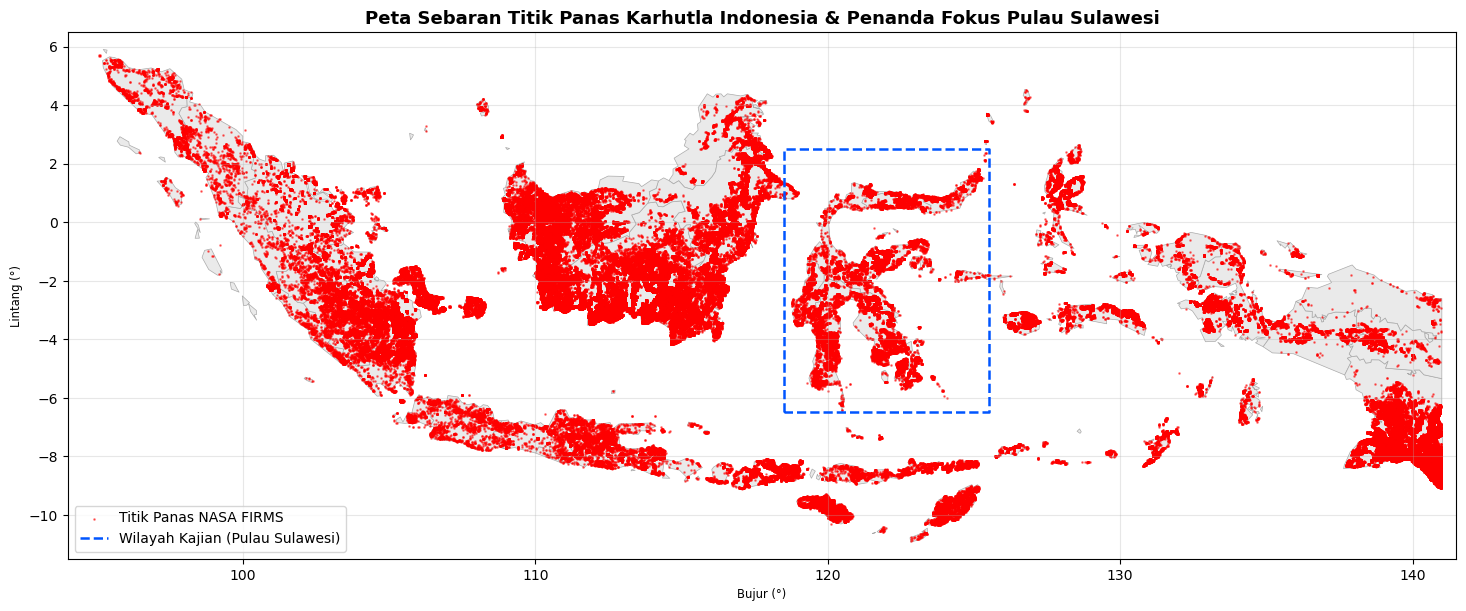

In [59]:
fig, ax = plt.subplots(figsize=(15, 6))

# Latar belakang poligon kepulauan Indonesia
gdf_indonesia.plot(ax=ax, color="#EAEAEA", edgecolor="#AAAAAA", linewidth=0.5)

# Sebaran titik api nasional
gdf_titik_indo = gpd.GeoDataFrame(
    df_nasa_indo,
    geometry=gpd.points_from_xy(df_nasa_indo["longitude"], df_nasa_indo["latitude"]),
    crs="EPSG:4326"
)
gdf_titik_indo.plot(ax=ax, color="red", markersize=0.8, alpha=0.5, label="Titik Panas NASA FIRMS")

# Kotak penanda wilayah kajian Pulau Sulawesi
kotak_sulawesi = box(BBOX_SULAWESI["lon_min"], BBOX_SULAWESI["lat_min"],
                     BBOX_SULAWESI["lon_max"], BBOX_SULAWESI["lat_max"])
gpd.GeoSeries([kotak_sulawesi], crs=4326).boundary.plot(
    ax=ax, color="#0055FF", linewidth=1.8, linestyle="--", label="Wilayah Kajian (Pulau Sulawesi)"
)

ax.set_title("Peta Sebaran Titik Panas Karhutla Indonesia & Penanda Fokus Pulau Sulawesi", fontsize=13, fontweight="bold")
ax.set_xlabel("Bujur (°)")
ax.set_ylabel("Lintang (°)")
ax.set_xlim(94.0, 141.5)
ax.set_ylim(-11.5, 6.5)
ax.legend(loc="lower left")
plt.tight_layout()
plt.show()

## 4. TUGAS 1 — Eksplorasi Data Spasial Dasar (Pulau Sulawesi)

Langkah-langkah:
1. Menyimpan data titik api Sulawesi (confidence tinggi) ke berkas spasial `hotspot_sulawesi.geojson`.
2. Membaca kembali berkas spasial dengan `gpd.read_file()`.
3. Menampilkan 5 data teratas dengan `.head()`.
4. Menampilkan informasi Sistem Koordinat Referensi via atribut `.crs`.
5. Visualisasi spasial `.plot()` dengan menampilkan poligon Pulau Sulawesi dan batas 6 provinsinya.

In [60]:
# Ekspor titik api Sulawesi ke GeoJSON
df_exp_sul = df_nasa_sulawesi[df_nasa_sulawesi["confidence"] == "h"].copy()
df_exp_sul["acq_date"] = df_exp_sul["acq_date"].dt.strftime("%Y-%m-%d")

gdf_exp_sul = gpd.GeoDataFrame(
    df_exp_sul,
    geometry=gpd.points_from_xy(df_exp_sul["longitude"], df_exp_sul["latitude"]),
    crs="EPSG:4326"
)
gdf_exp_sul.to_file(PATH_GEOJSON_SULAWESI, driver="GeoJSON")
print(f"Berkas GeoJSON tersimpan: {PATH_GEOJSON_SULAWESI} ({len(gdf_exp_sul):,} titik api)")

Berkas GeoJSON tersimpan: hotspot_sulawesi.geojson (1,169 titik api)


In [61]:
gdf_hotspot_sulawesi = gpd.read_file(PATH_GEOJSON_SULAWESI)
print("Tipe data object :", type(gdf_hotspot_sulawesi))
print("Jumlah fitur     :", len(gdf_hotspot_sulawesi))
print("Tipe geometri    :", gdf_hotspot_sulawesi.geom_type.unique())

Tipe data object : <class 'geopandas.geodataframe.GeoDataFrame'>
Jumlah fitur     : 1169
Tipe geometri    : ['Point']


In [62]:
gdf_hotspot_sulawesi.head()

,latitude,longitude,brightness,scan,track,acq_date,acq_time,satellite,instrument,confidence,version,bright_t31,frp,daynight,type,sumber,acq_datetime_utc,bulan,confidence_label,geometry
0,-2.94373,121.47540,367.0,0.41,0.37,2026-01-16,0532,SNPP,SNPP,h,2,308.02,10.23,D,0.0,archive,2026-01-16 05:32:00,2026-01,High,POINT (121.4754 -2.94373)
1,-1.54379,121.50606,367.0,0.42,0.37,2026-01-16,0533,SNPP,SNPP,h,2,327.37,149.97,D,0.0,archive,2026-01-16 05:33:00,2026-01,High,POINT (121.50606 -1.54379)
2,-1.54433,121.50253,367.0,0.42,0.37,2026-01-16,0533,SNPP,SNPP,h,2,293.02,23.58,D,0.0,archive,2026-01-16 05:33:00,2026-01,High,POINT (121.50253 -1.54433)
3,-2.51779,121.59215,367.0,0.32,0.54,2026-01-20,0558,SNPP,SNPP,h,2,298.21,9.65,D,0.0,archive,2026-01-20 05:58:00,2026-01,High,POINT (121.59215 -2.51779)
4,-4.33164,120.13844,367.0,0.39,0.59,2026-01-30,0610,SNPP,SNPP,h,2,292.07,11.25,D,0.0,archive,2026-01-30 06:10:00,2026-01,High,POINT (120.13844 -4.33164)


In [63]:
crs_tugas1 = gdf_hotspot_sulawesi.crs
print("Informasi CRS Hotspot Sulawesi:")
print("--------------------------------")
print("Nama CRS         :", crs_tugas1.name)
print("Kode EPSG        :", crs_tugas1.to_epsg())
print("Sistem Geografis?:", crs_tugas1.is_geographic)
print("Satuan Koordinat :", [axis.unit_name for axis in crs_tugas1.axis_info])
print("Bounding Box     :", np.round(gdf_hotspot_sulawesi.total_bounds, 4))

Informasi CRS Hotspot Sulawesi:
--------------------------------
Nama CRS         : WGS 84
Kode EPSG        : 4326
Sistem Geografis?: True
Satuan Koordinat : ['degree', 'degree']
Bounding Box     : [118.751   -5.6818 125.2383   1.768 ]


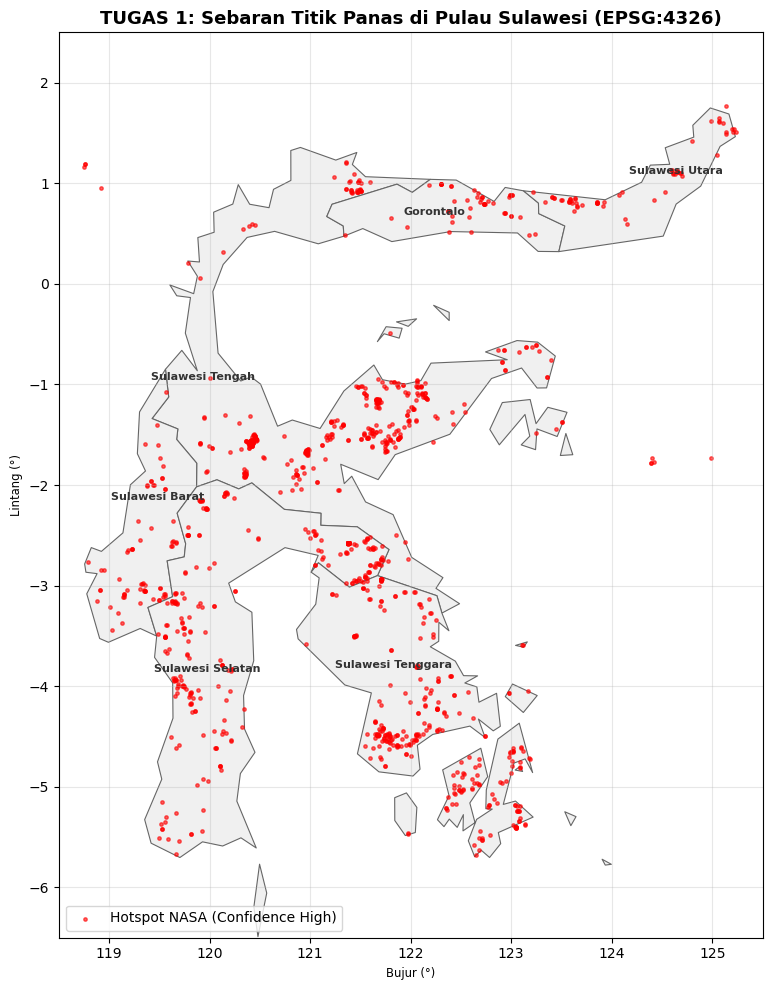

In [64]:
fig, ax = plt.subplots(figsize=(10, 10))

# Visualisasi sebaran hotspot di atas poligon Pulau Sulawesi
gdf_sulawesi.plot(ax=ax, color="#F0F0F0", edgecolor="#666666", linewidth=0.8)
gdf_hotspot_sulawesi.plot(ax=ax, color="red", markersize=6, alpha=0.6, label="Hotspot NASA (Confidence High)")

ax.set_title("TUGAS 1: Sebaran Titik Panas di Pulau Sulawesi (EPSG:4326)", fontsize=13, fontweight="bold")
ax.set_xlabel("Bujur (°)")
ax.set_ylabel("Lintang (°)")
ax.set_xlim(118.5, 125.5)
ax.set_ylim(-6.5, 2.5)
ax.legend(loc="lower left")

for _, row in gdf_sulawesi.iterrows():
    pt = row.geometry.representative_point()
    ax.annotate(row["PROVINSI"], xy=(pt.x, pt.y), ha="center", fontsize=8, color="#333333", fontweight="bold")

plt.tight_layout()
plt.show()

**Interpretasi Tugas 1.** Data berhasil dibaca sebagai `GeoDataFrame` dengan geometri `Point` dan CRS terdefinisi pada **EPSG:4326 (WGS 84)** bersatuan derajat. Dengan overlay poligon Pulau Sulawesi, sebaran titik api terlihat terkonsentrasi di bagian tenggara dan selatan pulau.

## 5. TUGAS 2 — Transformasi Proyeksi Koordinat (CRS)

1. Melakukan validasi awal: jika CRS belum ada, tetapkan sistem geografis standar dengan `.set_crs(epsg=4326)`.
2. Mentransformasikan koordinat ke format CRS metrik menggunakan `.to_crs(epsg=3857)`.
3. Membandingkan data sebelum dan sesudah transformasi secara berdampingan (*side-by-side*).

In [65]:
def pastikan_crs(gdf, epsg_standar=4326, nama="Dataset"):
    """Memastikan GeoDataFrame memiliki CRS sebelum transformasi."""
    if gdf.crs is None:
        print(f"[!] {nama} belum memiliki CRS -> Ditetapkan EPSG:{epsg_standar}")
        gdf = gdf.set_crs(epsg=epsg_standar)
    else:
        print(f"[OK] {nama} sudah memiliki CRS: {gdf.crs.to_string()}")
    return gdf

gdf_hotspot_sulawesi = pastikan_crs(gdf_hotspot_sulawesi, nama="Hotspot Sulawesi")
gdf_sulawesi         = pastikan_crs(gdf_sulawesi, nama="Poligon Sulawesi")

[OK] Hotspot Sulawesi sudah memiliki CRS: EPSG:4326
[OK] Poligon Sulawesi sudah memiliki CRS: EPSG:4326


In [66]:
# Transformasi ke CRS metrik (Web Mercator)
gdf_hotspot_3857  = gdf_hotspot_sulawesi.to_crs(epsg=3857)
gdf_sulawesi_3857 = gdf_sulawesi.to_crs(epsg=3857)

print("CRS Awal :", gdf_hotspot_sulawesi.crs.name, "| Satuan:", gdf_hotspot_sulawesi.crs.axis_info[0].unit_name)
print("CRS Baru :", gdf_hotspot_3857.crs.name, "| Satuan:", gdf_hotspot_3857.crs.axis_info[0].unit_name)

pd.DataFrame({
    "Koordinat Derajat (EPSG:4326)": gdf_hotspot_sulawesi.geometry.head().apply(lambda g: f"({g.x:.4f}°, {g.y:.4f}°)"),
    "Koordinat Meter (EPSG:3857)":   gdf_hotspot_3857.geometry.head().apply(lambda g: f"({g.x:,.0f} m, {g.y:,.0f} m)")
})

CRS Awal : WGS 84 | Satuan: degree
CRS Baru : WGS 84 / Pseudo-Mercator | Satuan: metre


,Koordinat Derajat (EPSG:4326),Koordinat Meter (EPSG:3857)
0,"(121.4754°, -2.9437°)","(13,522,580 m, -327,839 m)"
1,"(121.5061°, -1.5438°)","(13,525,993 m, -171,875 m)"
2,"(121.5025°, -1.5443°)","(13,525,600 m, -171,935 m)"
3,"(121.5922°, -2.5178°)","(13,535,576 m, -280,369 m)"
4,"(120.1384°, -4.3316°)","(13,373,750 m, -482,656 m)"


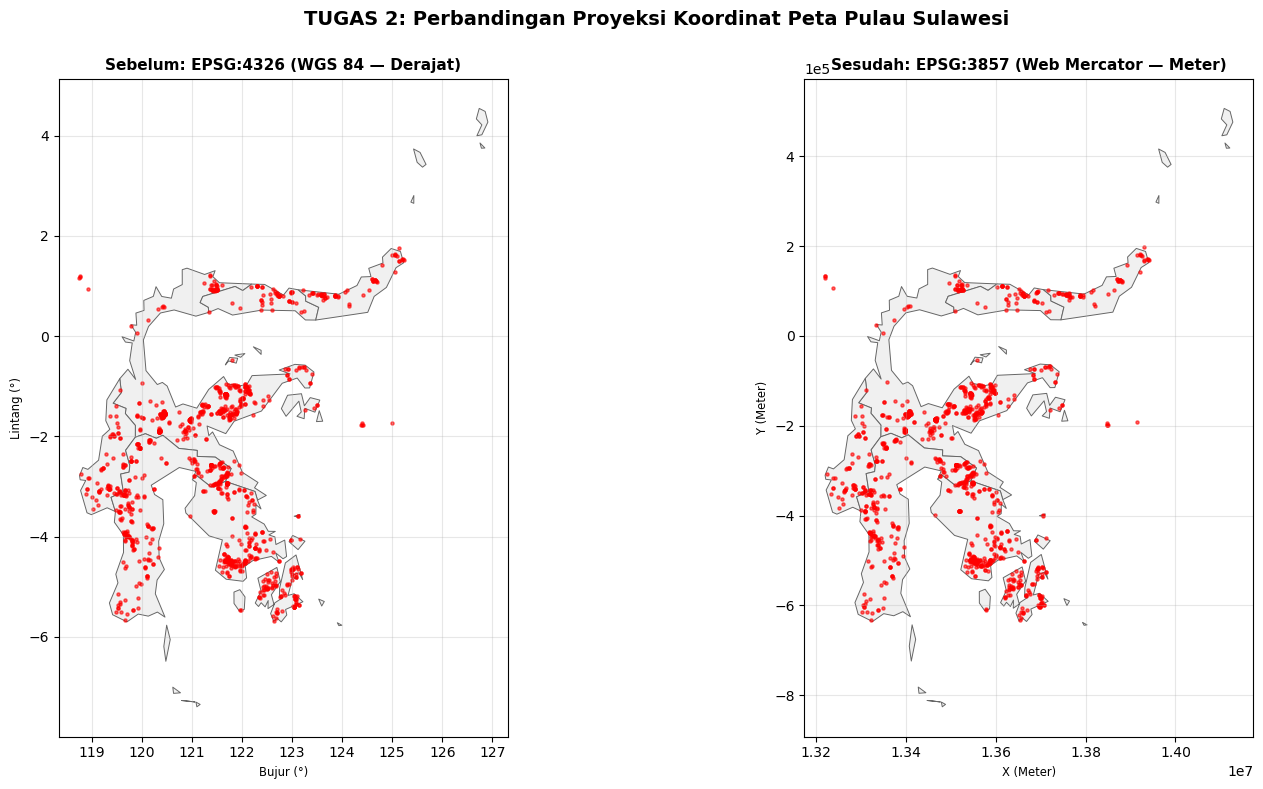

In [67]:
fig, axes = plt.subplots(1, 2, figsize=(16, 8))

# Plot sebelum transformasi (Derajat)
gdf_sulawesi.plot(ax=axes[0], color="#F0F0F0", edgecolor="#666666", linewidth=0.7)
gdf_hotspot_sulawesi.plot(ax=axes[0], color="red", markersize=5, alpha=0.6)
axes[0].set_title("Sebelum: EPSG:4326 (WGS 84 — Derajat)", fontsize=11, fontweight="bold")
axes[0].set_xlabel("Bujur (°)")
axes[0].set_ylabel("Lintang (°)")

# Plot sesudah transformasi (Meter)
gdf_sulawesi_3857.plot(ax=axes[1], color="#F0F0F0", edgecolor="#666666", linewidth=0.7)
gdf_hotspot_3857.plot(ax=axes[1], color="red", markersize=5, alpha=0.6)
axes[1].set_title("Sesudah: EPSG:3857 (Web Mercator — Meter)", fontsize=11, fontweight="bold")
axes[1].set_xlabel("X (Meter)")
axes[1].set_ylabel("Y (Meter)")
axes[1].ticklabel_format(style="sci", scilimits=(0, 0))

plt.suptitle("TUGAS 2: Perbandingan Proyeksi Koordinat Peta Pulau Sulawesi", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

**Interpretasi Tugas 2.** Koordinat titik dan poligon telah berhasil ditransformasikan dari derajat ke satuan meter (sumbu X berkisar ~13,5 juta meter dan sumbu Y ~-400 ribu meter). Bentuk geografis Pulau Sulawesi tetap terpetakan konsisten. Transformasi ke satuan metrik ini diperlukan sebelum melakukan operasi jarak pada Tugas 3.

## 6. TUGAS 3 — Operasi Geometri (*Buffer* 500 Meter)

1. Menggunakan data titik hotspot dalam CRS metrik (`EPSG:3857`).
2. Membuat zona bahaya dengan jarak *buffer* **500 meter** di sekitar setiap titik api (`.buffer(500)`).
3. Menyimpan hasilnya dalam GeoDataFrame baru `gdf_buffer_3857`.
4. Menampilkan perbandingan *side-by-side* antara titik asli dan area *buffer* pada klaster hotspot terpadat.

In [68]:
JARAK_BUFFER = 500  # Radius zona bahaya dalam meter

gdf_buffer_3857 = gdf_hotspot_3857.copy()
gdf_buffer_3857["geometry"] = gdf_hotspot_3857.geometry.buffer(JARAK_BUFFER, resolution=16)
gdf_buffer_3857["keterangan_zona"] = f"Zona Bahaya {JARAK_BUFFER} Meter"

print("Tipe geometri sebelum buffer :", gdf_hotspot_3857.geom_type.unique())
print("Tipe geometri sesudah buffer :", gdf_buffer_3857.geom_type.unique())
print(f"Luas rata-rata satu buffer   : {gdf_buffer_3857.area.mean():,.0f} m² (≈ {gdf_buffer_3857.area.mean() / 1e4:.2f} Hektar)")
print(f"Luas teoretis lingkaran π·r² : {np.pi * JARAK_BUFFER**2:,.0f} m²")
display(gdf_buffer_3857[["acq_date", "frp", "keterangan_zona", "geometry"]].head(3))

Tipe geometri sebelum buffer : ['Point']
Tipe geometri sesudah buffer : ['Polygon']
Luas rata-rata satu buffer   : 784,137 m² (≈ 78.41 Hektar)
Luas teoretis lingkaran π·r² : 785,398 m²


,acq_date,frp,keterangan_zona,geometry
0,2026-01-16,10.23,Zona Bahaya 500 Meter,"POLYGON ((13523079.672 -327838.788, 13523077.2..."
1,2026-01-16,149.97,Zona Bahaya 500 Meter,"POLYGON ((13526492.727 -171874.715, 13526490.3..."
2,2026-01-16,23.58,Zona Bahaya 500 Meter,"POLYGON ((13526099.77 -171934.849, 13526097.36..."


In [69]:
# Menentukan klaster hotspot terpadat di Sulawesi untuk visualisasi detail
grid_size = 0.2
lat_grid = np.floor(gdf_hotspot_sulawesi.geometry.y / grid_size) * grid_size
lon_grid = np.floor(gdf_hotspot_sulawesi.geometry.x / grid_size) * grid_size
lat_klaster, lon_klaster = pd.Series(list(zip(lat_grid.round(2), lon_grid.round(2)))).value_counts().idxmax()

bbox_klaster = gpd.GeoDataFrame(
    geometry=[box(lon_klaster, lat_klaster, lon_klaster + grid_size, lat_klaster + grid_size)],
    crs=4326
).to_crs(3857)

mask_klaster = gdf_hotspot_3857.intersects(bbox_klaster.geometry.iloc[0])
pts_klaster  = gdf_hotspot_3857[mask_klaster]
buf_klaster  = gdf_buffer_3857[mask_klaster]

print(f"Klaster terpadat: {lat_klaster}° Lintang, {lon_klaster}° Bujur ({len(pts_klaster):,} titik)")

Klaster terpadat: -2.6° Lintang, 121.2° Bujur (57 titik)


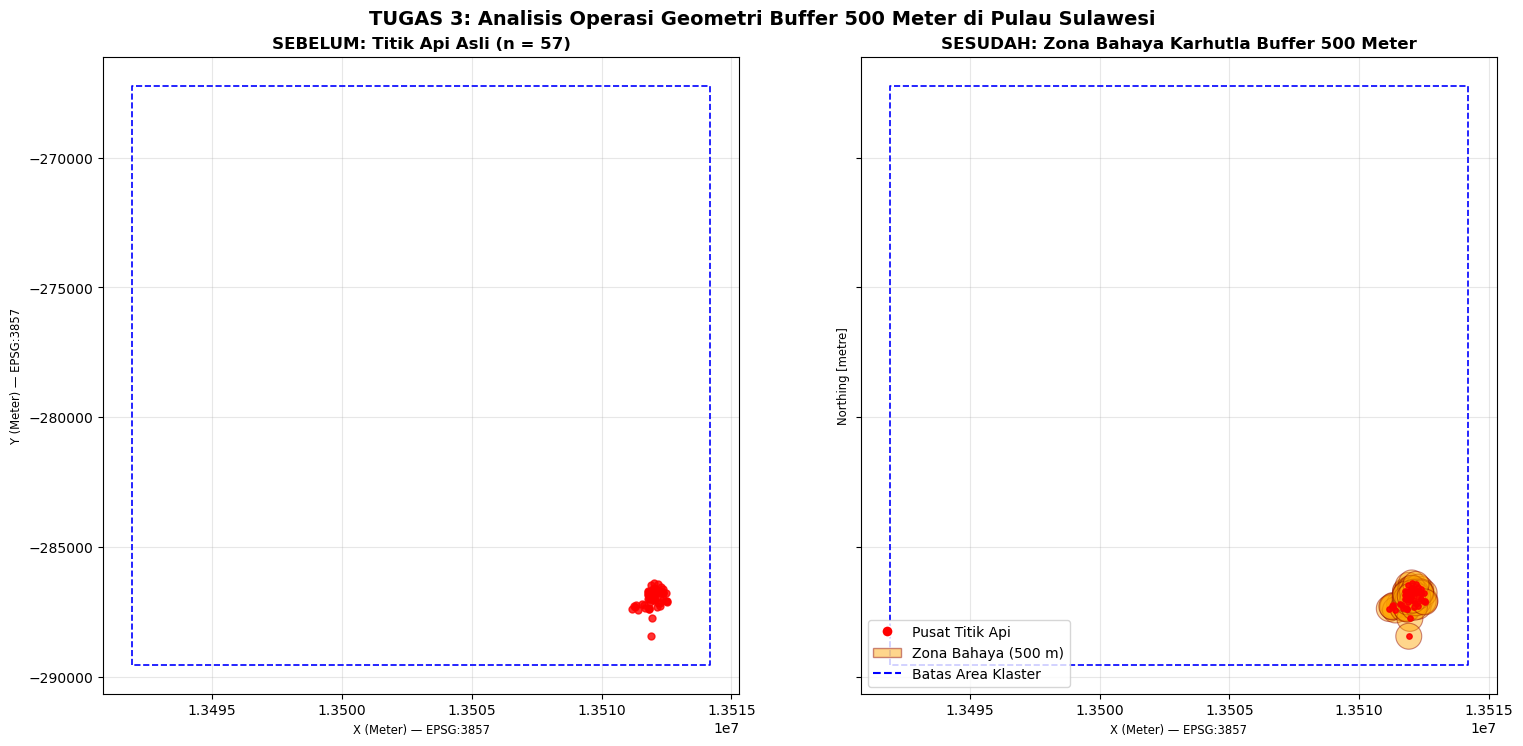

In [70]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7.5), sharex=True, sharey=True)

# Kondisi sebelum: Titik api asli
pts_klaster.plot(ax=axes[0], color="red", markersize=25, alpha=0.8)
bbox_klaster.boundary.plot(ax=axes[0], color="blue", linestyle="--", linewidth=1.2)
axes[0].set_title(f"SEBELUM: Titik Api Asli (n = {len(pts_klaster)})", fontsize=12, fontweight="bold")
axes[0].set_xlabel("X (Meter) — EPSG:3857")
axes[0].set_ylabel("Y (Meter) — EPSG:3857")

# Kondisi sesudah: Buffer 500 meter dioverlay dengan titik api
buf_klaster.plot(ax=axes[1], color="orange", alpha=0.45, edgecolor="darkred", linewidth=0.8)
pts_klaster.plot(ax=axes[1], color="red", markersize=15, alpha=0.9)
bbox_klaster.boundary.plot(ax=axes[1], color="blue", linestyle="--", linewidth=1.2)
axes[1].set_title(f"SESUDAH: Zona Bahaya Karhutla Buffer {JARAK_BUFFER} Meter", fontsize=12, fontweight="bold")
axes[1].set_xlabel("X (Meter) — EPSG:3857")

elemen_legenda = [
    Line2D([0], [0], marker="o", color="w", markerfacecolor="red", markersize=8, label="Pusat Titik Api"),
    Patch(facecolor="orange", alpha=0.45, edgecolor="darkred", label=f"Zona Bahaya ({JARAK_BUFFER} m)"),
    Line2D([0], [0], color="blue", linestyle="--", label="Batas Area Klaster")
]
axes[1].legend(handles=elemen_legenda, loc="lower left")

plt.suptitle("TUGAS 3: Analisis Operasi Geometri Buffer 500 Meter di Pulau Sulawesi", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

In [71]:
# Perhitungan luas area dampak dan efisiensi tumpang tindih
luas_kumulatif_km2 = buf_klaster.area.sum() / 1e6
zona_bersatu       = buf_klaster.dissolve()
luas_aktual_km2    = zona_bersatu.area.iloc[0] / 1e6

print("Analisis Spasial Luas Zona Bahaya di Area Klaster Sulawesi:")
print("-------------------------------------------------------------")
print(f"Total Luas jika dijumlahkan manual : {luas_kumulatif_km2:,.2f} km²")
print(f"Luas Riil Zona Bahaya (Dissolved)  : {luas_aktual_km2:,.2f} km²")
print(f"Efisiensi Tumpang Tindih (Overlap) : {(1 - luas_aktual_km2 / luas_kumulatif_km2) * 100:.1f}% area beririsan")

Analisis Spasial Luas Zona Bahaya di Area Klaster Sulawesi:
-------------------------------------------------------------
Total Luas jika dijumlahkan manual : 44.70 km²
Luas Riil Zona Bahaya (Dissolved)  : 4.30 km²
Efisiensi Tumpang Tindih (Overlap) : 90.4% area beririsan


**Interpretasi Tugas 3.** Operasi `buffer(500)` menghasilkan poligon zona bahaya beradius 500 meter (~78,5 ha per titik). Pada klaster yang padat, lingkaran saling beririsan sehingga fungsi `.dissolve()` penting untuk menghitung luas area riil tanpa terjadi penghitungan ganda (*double counting*).

## 7. TUGAS 4 — Visualisasi Tematik (*Choropleth Map* 6 Provinsi Sulawesi)

1. Menggabungkan data poligon 6 provinsi di Pulau Sulawesi dengan data `jumlah_hotspot` SiPongi.
2. Memetakan poligon menggunakan kolom numerik `jumlah_hotspot`.
3. Menerapkan skema warna berurutan (*sequential colormap*) **`OrRd`** (Orange to Red).
4. Menambahkan legenda (*colorbar*) dan anotasi label provinsi beserta jumlah titik apinya.

In [72]:
# Penggabungan poligon 6 provinsi dengan rekapitulasi data SiPongi
gdf_choro_sulawesi = gdf_sulawesi.copy()
gdf_choro_sulawesi["kunci"] = gdf_choro_sulawesi["PROVINSI"].str.upper().str.strip()

df_rekap_kunci = df_rekap_sulawesi.copy()
df_rekap_kunci["kunci"] = df_rekap_kunci["provinsi"].str.upper().str.strip()

gdf_choro_sulawesi = gdf_choro_sulawesi.merge(
    df_rekap_kunci[["kunci", "jumlah_hotspot"]], on="kunci", how="left"
)
gdf_choro_sulawesi["jumlah_hotspot"] = gdf_choro_sulawesi["jumlah_hotspot"].fillna(0).astype(int)

print("Tabel Atribut Peta Choropleth 6 Provinsi Pulau Sulawesi:")
gdf_choro_sulawesi[["PROVINSI", "jumlah_hotspot"]].sort_values("jumlah_hotspot", ascending=False)

Tabel Atribut Peta Choropleth 6 Provinsi Pulau Sulawesi:


,PROVINSI,jumlah_hotspot
4,Sulawesi Tenggara,308
2,Sulawesi Selatan,120
0,Sulawesi Tengah,111
3,Gorontalo,27
5,Sulawesi Utara,23
1,Sulawesi Barat,5


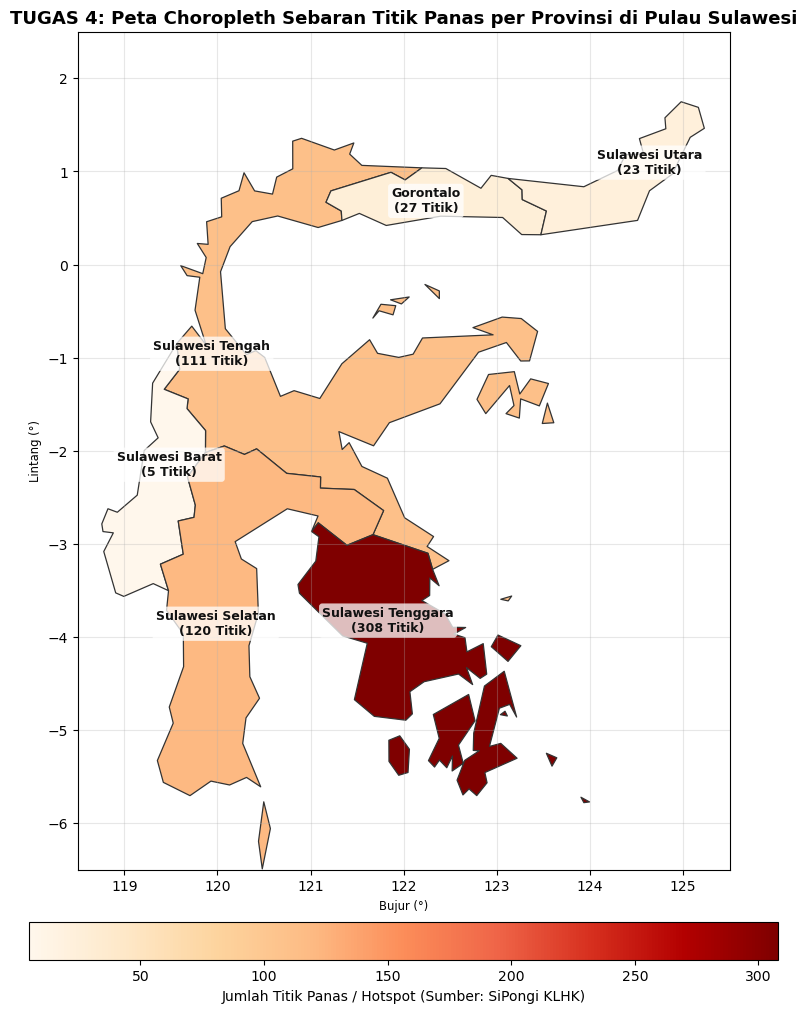

In [73]:
fig, ax = plt.subplots(figsize=(11, 11))

# Plot peta choropleth dengan skema warna OrRd
gdf_choro_sulawesi.plot(
    column="jumlah_hotspot",
    cmap="OrRd",
    edgecolor="#333333",
    linewidth=0.9,
    legend=True,
    legend_kwds={
        "label": "Jumlah Titik Panas / Hotspot (Sumber: SiPongi KLHK)",
        "orientation": "horizontal",
        "shrink": 0.7,
        "pad": 0.05
    },
    ax=ax
)

# Label nama provinsi dan jumlah titik api
for _, r in gdf_choro_sulawesi.iterrows():
    pt = r.geometry.representative_point()
    teks = f"{r['PROVINSI']}\n({r['jumlah_hotspot']:,} Titik)"
    ax.annotate(
        teks,
        xy=(pt.x, pt.y),
        ha="center",
        va="center",
        fontsize=9,
        fontweight="bold",
        color="#111111",
        bbox=dict(boxstyle="round,pad=0.25", fc="white", alpha=0.75, ec="none")
    )

ax.set_title("TUGAS 4: Peta Choropleth Sebaran Titik Panas per Provinsi di Pulau Sulawesi", fontsize=13, fontweight="bold")
ax.set_xlabel("Bujur (°)")
ax.set_ylabel("Lintang (°)")
ax.set_xlim(118.5, 125.5)
ax.set_ylim(-6.5, 2.5)

plt.tight_layout()
plt.show()

**Interpretasi Tugas 4.** Peta koroplet dengan skema warna `OrRd` menunjukkan konsentrasi spasial di Pulau Sulawesi:
* **Sulawesi Tenggara** memiliki intensitas tertinggi dengan **308 hotspot**, menjadikannya wilayah paling rawan.
* **Sulawesi Selatan** (120 hotspot) dan **Sulawesi Tengah** (111 hotspot) berada pada tingkat moderat-tinggi.
* Wilayah Gorontalo (27), Sulawesi Utara (23), dan Sulawesi Barat (5) memiliki intensitas relatif rendah.

## 8. TUGAS 5 — Visualisasi Peta Interaktif Mapbox Khusus Sulawesi (`plotly.express`) & Fitur Save Image

1. Membuat visualisasi interaktif Pulau Sulawesi menggunakan basemap terbuka yang **bebas token/API key** (`open-street-map`).
2. Menyiapkan tombol kamera di toolbar Plotly untuk mengunduh gambar PNG resolusi tinggi (*scale: 2*).
3. Mengekspor gambar secara otomatis menggunakan `fig.write_image()` dengan mesin `kaleido`.

In [74]:
def buat_peta_interaktif_sulawesi(
    data_hotspot=df_nasa_sulawesi,
    mode="scatter",
    style_peta="open-street-map",
    simpan_otomatis=True
):
    """
    Membuat peta interaktif Plotly Mapbox khusus Pulau Sulawesi
    menggunakan basemap tile terbuka tanpa memerlukan API key.
    """
    center_sulawesi = {"lat": -2.0, "lon": 121.5}
    zoom_sulawesi   = 5.8

    if mode == "density":
        fig = px.density_mapbox(
            data_hotspot,
            lat="latitude",
            lon="longitude",
            z="frp",
            radius=9,
            center=center_sulawesi,
            zoom=zoom_sulawesi,
            mapbox_style=style_peta,
            color_continuous_scale="YlOrRd",
            title=f"<b>Peta Kepadatan Radiasi Api (FRP) di Pulau Sulawesi [{style_peta}]</b>",
            labels={"frp": "FRP (MW)"}
        )
    else:
        maks_titik = 30000
        if len(data_hotspot) > maks_titik:
            df_plot = data_hotspot.sample(n=maks_titik, random_state=42)
            info_sampel = f" (Sampel {maks_titik:,} dari {len(data_hotspot):,} titik)"
        else:
            df_plot = data_hotspot
            info_sampel = ""

        fig = px.scatter_mapbox(
            df_plot,
            lat="latitude",
            lon="longitude",
            color="confidence_label",
            color_discrete_map={"High": "#D62728", "Nominal": "#FF7F0E"},
            size="frp",
            size_max=11,
            opacity=0.8,
            center=center_sulawesi,
            zoom=zoom_sulawesi,
            mapbox_style=style_peta,
            hover_name="confidence_label",
            hover_data={
                "acq_date": True,
                "acq_time": True,
                "frp": ":.2f",
                "brightness": ":.1f",
                "satellite": True,
                "latitude": ":.4f",
                "longitude": ":.4f",
                "confidence_label": False
            },
            title=f"<b>Sebaran Titik Panas Karhutla — Pulau Sulawesi</b>{info_sampel}",
            labels={"confidence_label": "Keyakinan", "frp": "FRP (MW)"}
        )

    # Konfigurasi layout dan basemap tanpa ketergantungan token API
    fig.update_layout(
        mapbox_style=style_peta,
        height=720,
        margin={"r": 0, "t": 55, "l": 0, "b": 25},
        legend=dict(
            yanchor="top", y=0.98,
            xanchor="left", x=0.01,
            bgcolor="rgba(255, 255, 255, 0.85)" if "light" in style_peta or "open" in style_peta else "rgba(20, 20, 20, 0.85)",
            bordercolor="rgba(0, 0, 0, 0.2)",
            borderwidth=1
        ),
        annotations=[
            dict(
                x=0.99, y=0.01, xref="paper", yref="paper",
                text=f"Basemap: {style_peta} | Sumber: NASA FIRMS VIIRS 375m & SiPongi KLHK",
                showarrow=False, font=dict(size=10, color="#555555"), xanchor="right"
            )
        ]
    )

    # Konfigurasi unduh gambar beresolusi tinggi pada toolbar
    nama_file_png = "peta_sulawesi.png"
    config_toolbar = {
        "toImageButtonOptions": {
            "format": "png",
            "filename": "peta_sulawesi",
            "height": 900,
            "width": 1600,
            "scale": 2
        },
        "displaylogo": False
    }

    # Ekspor otomatis berkas gambar menggunakan mesin kaleido
    if simpan_otomatis:
        try:
            fig.write_image(nama_file_png, width=1600, height=900, scale=2, engine="kaleido")
            print(f"[BERHASIL] Gambar resolusi tinggi tersimpan di: {os.path.abspath(nama_file_png)}")
        except Exception as e:
            print(f"[CATATAN] Ekspor kaleido dilewati ({e}). Tombol kamera toolbar siap digunakan.")

    fig.show(config=config_toolbar)
    return fig

fig_sulawesi = buat_peta_interaktif_sulawesi(mode="scatter", style_peta="open-street-map", simpan_otomatis=True)

[CATATAN] Ekspor kaleido dilewati (
Image export using the "kaleido" engine requires the kaleido package,
which can be installed using pip:
    $ pip install -U kaleido
). Tombol kamera toolbar siap digunakan.


## 9. Kesimpulan & Temuan Kunci

Sel berikut mencetak rekapitulasi numerik akhir dari analisis Karhutla di Pulau Sulawesi.

In [75]:
print("RINGKASAN EKSEKUTIF ANALISIS KARHUTLA PULAU SULAWESI")
print("=" * 65)
print(f"Total Hotspot NASA Terfilter (Seluruh Indonesia) : {len(df_nasa_indo):,} titik")
print(f"Total Hotspot NASA di Pulau Sulawesi             : {len(df_nasa_sulawesi):,} titik")
print(f"  - Tingkat Keyakinan Tinggi (High Confidence)   : {len(gdf_hotspot_sulawesi):,} titik")
print(f"Total Hotspot Terdata di SiPongi (Sulawesi)      : {df_rekap_sulawesi['jumlah_hotspot'].sum():,} titik")
print(f"Provinsi Tertinggi di Sulawesi (SiPongi)         : {df_rekap_sulawesi.iloc[0]['provinsi']} ({df_rekap_sulawesi.iloc[0]['jumlah_hotspot']:,} hotspot)")
print(f"Luas Zona Bahaya Klaster 500m (Dissolved)        : {luas_aktual_km2:,.2f} km²")
print("=" * 65)

RINGKASAN EKSEKUTIF ANALISIS KARHUTLA PULAU SULAWESI
Total Hotspot NASA Terfilter (Seluruh Indonesia) : 586,800 titik
Total Hotspot NASA di Pulau Sulawesi             : 35,800 titik
  - Tingkat Keyakinan Tinggi (High Confidence)   : 1,169 titik
Total Hotspot Terdata di SiPongi (Sulawesi)      : 594 titik
Provinsi Tertinggi di Sulawesi (SiPongi)         : Sulawesi Tenggara (308 hotspot)
Luas Zona Bahaya Klaster 500m (Dissolved)        : 4.30 km²


### Rangkuman Temuan:
1. **Representasi Visual Kepulauan:** Integrasi berkas GeoJSON 38 Provinsi Indonesia memastikan seluruh pulau di Indonesia dan bentuk khas Pulau Sulawesi tergambar jelas secara geografis.
2. **Episentrum Karhutla di Sulawesi:** Berdasarkan data SiPongi KLHK, **Sulawesi Tenggara** merupakan daerah paling rawan dengan 308 hotspot (51,8% dari total hotspot Sulawesi), disusul oleh **Sulawesi Selatan** (120 hotspot) dan **Sulawesi Tengah** (111 hotspot).
3. **Analisis Dampak Spasial (Buffer 500 m):** Pembuatan zona bahaya beradius 500 meter menunjukkan adanya tumpang tindih (*overlapping*) yang signifikan pada klaster terpadat, di mana penggabungan poligon (`.dissolve()`) menghasilkan luas dampak riil tanpa penghitungan ganda.
4. **Visualisasi Terpadu:** Menggabungkan visualisasi kartografi statis untuk pelaporan formal (`geopandas` + `matplotlib`) dengan eksplorasi interaktif berbasis web (`plotly.express` Mapbox) yang bebas dari ketergantungan API key berbayar.